In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "events.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data exists:", DATA_PATH.exists())
print("Figures directory:", FIGURES_DIR)
print("Tables directory:", TABLES_DIR)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {DATA_PATH}. "
        "Проверь структуру проекта и расположение events.csv."
    )

Project root: /Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics
Data exists: True
Figures directory: /Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics/reports/figures
Tables directory: /Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics/reports/tables


In [ ]:
events = pd.read_csv(DATA_PATH)

required_columns = {"visitorid", "timestamp"}
missing_columns = required_columns - set(events.columns)

if missing_columns:
    raise ValueError(f"В датасете отсутствуют обязательные столбцы: {missing_columns}")

events = events[["visitorid", "timestamp"]].copy()
events = events.dropna(subset=["visitorid", "timestamp"])

events["timestamp"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True,
    errors="coerce"
)
events = events.dropna(subset=["timestamp"])

events["visitorid"] = events["visitorid"].astype("int64")

print(f"Количество событий после подготовки: {len(events):,}")
print(f"Количество уникальных пользователей: {events['visitorid'].nunique():,}")
print(f"Начало периода: {events['timestamp'].min()}")
print(f"Конец периода: {events['timestamp'].max()}")

events.head()

Количество событий после подготовки: 2,756,101
Количество уникальных пользователей: 1,407,580
Начало периода: 2015-05-03 03:00:04.384000+00:00
Конец периода: 2015-09-18 02:59:47.788000+00:00


,visitorid,timestamp
0,257597,2015-06-02 05:02:12.117+00:00
1,992329,2015-06-02 05:50:14.164+00:00
2,111016,2015-06-02 05:13:19.827+00:00
3,483717,2015-06-02 05:12:35.914+00:00
4,951259,2015-06-02 05:02:17.106+00:00


In [5]:
first_activity = (
    events.groupby("visitorid", as_index=False)["timestamp"]
    .min()
    .rename(columns={"timestamp": "first_activity"})
)

first_activity["cohort_month"] = (
    first_activity["first_activity"].dt.to_period("M").dt.to_timestamp()
)

first_activity.head()

/var/folders/gk/l4rj7d3x7wj7wlw6z7x421mr0000gn/T/ipykernel_3508/4231562204.py:8: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  first_activity["first_activity"].dt.to_period("M").dt.to_timestamp()


,visitorid,first_activity,cohort_month
0,0,2015-09-11 20:49:49.439+00:00,2015-09-01
1,1,2015-08-13 17:46:06.444+00:00,2015-08-01
2,2,2015-08-07 17:51:44.567+00:00,2015-08-01
3,3,2015-08-01 07:10:35.296+00:00,2015-08-01
4,4,2015-09-15 21:24:27.167+00:00,2015-09-01


In [ ]:
events["activity_month"] = (
    events["timestamp"].dt.to_period("M").dt.to_timestamp()
)

user_month_activity = (
    events[["visitorid", "activity_month"]]
    .drop_duplicates()
    .merge(
        first_activity[["visitorid", "cohort_month"]],
        on="visitorid",
        how="left"
    )
)

user_month_activity["cohort_index"] = (
    (user_month_activity["activity_month"].dt.year -
     user_month_activity["cohort_month"].dt.year) * 12
    +
    (user_month_activity["activity_month"].dt.month -
     user_month_activity["cohort_month"].dt.month)
)

assert (user_month_activity["cohort_index"] >= 0).all()

user_month_activity.head()

/var/folders/gk/l4rj7d3x7wj7wlw6z7x421mr0000gn/T/ipykernel_3508/1308175119.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  events["timestamp"].dt.to_period("M").dt.to_timestamp()


,visitorid,activity_month,cohort_month,cohort_index
0,257597,2015-06-01,2015-06-01,0
1,992329,2015-06-01,2015-05-01,1
2,111016,2015-06-01,2015-05-01,1
3,483717,2015-06-01,2015-06-01,0
4,951259,2015-06-01,2015-06-01,0


In [7]:
cohort_sizes = (
    first_activity.groupby("cohort_month")["visitorid"]
    .nunique()
    .rename("cohort_size")
)

cohort_activity = (
    user_month_activity
    .groupby(["cohort_month", "cohort_index"])["visitorid"]
    .nunique()
    .rename("active_users")
    .reset_index()
)

cohort_activity = cohort_activity.merge(
    cohort_sizes,
    on="cohort_month",
    how="left"
)

cohort_activity["retention_rate"] = (
    cohort_activity["active_users"] / cohort_activity["cohort_size"]
)

cohort_sizes.to_frame()

,cohort_size
cohort_month,
2015-05-01,307574
2015-06-01,299189
2015-07-01,355765
2015-08-01,288328
2015-09-01,156724


In [8]:
retention_matrix = cohort_activity.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="retention_rate"
).sort_index()

retention_matrix.index = retention_matrix.index.strftime("%Y-%m")
retention_matrix.columns = [f"Month {int(col)}" for col in retention_matrix.columns]

retention_matrix

,Month 0,Month 1,Month 2,Month 3,Month 4
cohort_month,,,,,
2015-05,1.0000,0.0476,0.0286,0.0189,0.0105
2015-06,1.0000,0.0423,0.0202,0.0096,NaN
2015-07,1.0000,0.0308,0.0109,NaN,NaN
2015-08,1.0000,0.0243,NaN,NaN,NaN
2015-09,1.0000,NaN,NaN,NaN,NaN


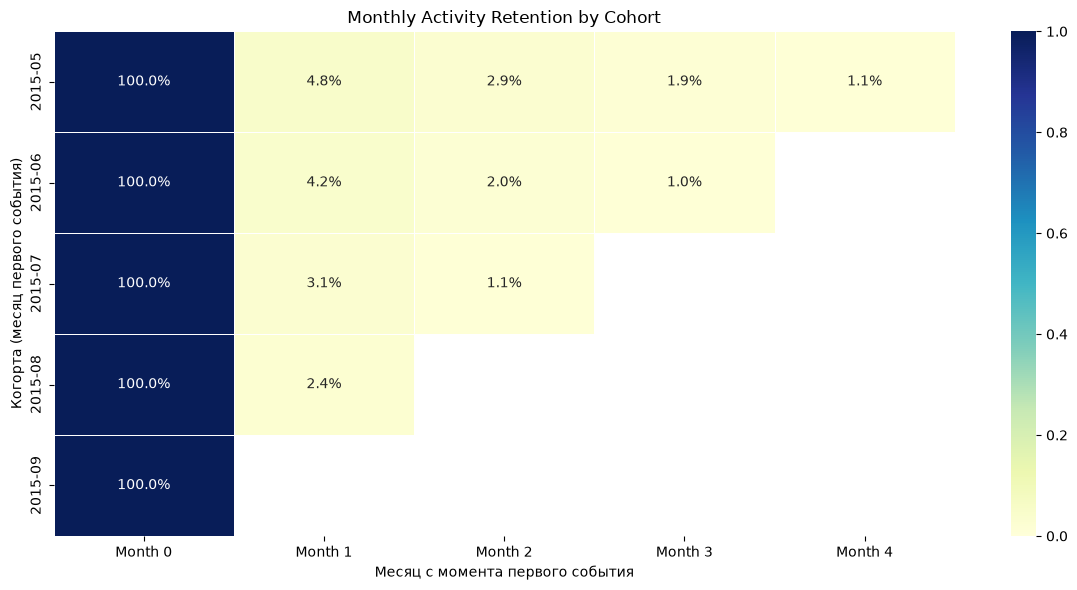

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt=".1%",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=1,
    ax=ax
)

ax.set_title("Monthly Activity Retention by Cohort")
ax.set_xlabel("Месяц с момента первого события")
ax.set_ylabel("Когорта (месяц первого события)")
plt.tight_layout()

fig.savefig(FIGURES_DIR / "04_cohort_retention_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
cohort_summary = cohort_sizes.reset_index()
cohort_summary["cohort_month"] = cohort_summary["cohort_month"].dt.strftime("%Y-%m")

cohort_summary

,cohort_month,cohort_size
0,2015-05,307574
1,2015-06,299189
2,2015-07,355765
3,2015-08,288328
4,2015-09,156724


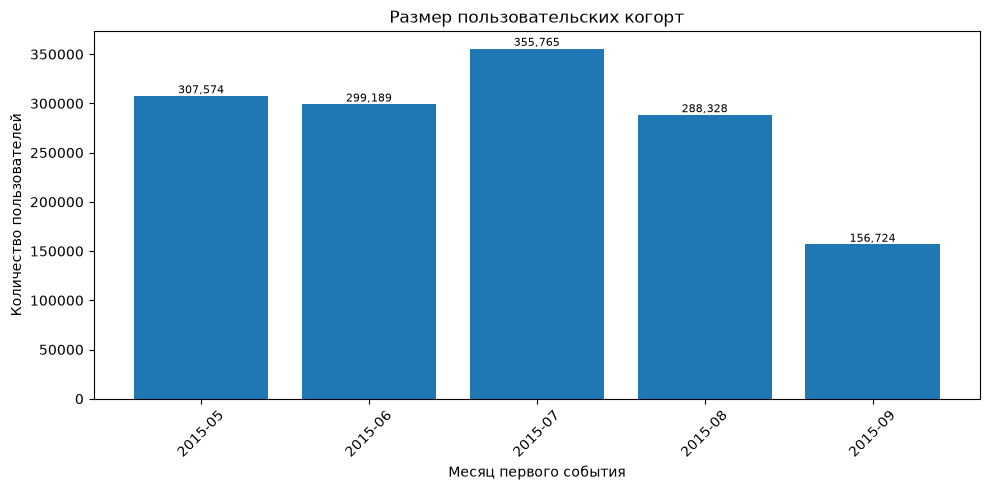

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

plot_data = cohort_summary.copy()
bars = ax.bar(plot_data["cohort_month"], plot_data["cohort_size"])

ax.set_title("Размер пользовательских когорт")
ax.set_xlabel("Месяц первого события")
ax.set_ylabel("Количество пользователей")
ax.tick_params(axis="x", rotation=45)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
fig.savefig(FIGURES_DIR / "04_cohort_sizes.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
data_start = events["timestamp"].min()
data_end = events["timestamp"].max()

last_calendar_month = data_end.to_period("M")
last_month_end = last_calendar_month.end_time.tz_localize("UTC")
last_month_is_partial = data_end < last_month_end

print("Начало наблюдения:", data_start)
print("Конец наблюдения:", data_end)
print("Последний календарный месяц:", str(last_calendar_month))
print("Последний месяц неполный:", last_month_is_partial)

if last_month_is_partial:
    print(
        "Внимание: когорта последнего месяца и retention в последнем месяце "
        "рассчитываются по неполному периоду наблюдения."
    )

Начало наблюдения: 2015-05-03 03:00:04.384000+00:00
Конец наблюдения: 2015-09-18 02:59:47.788000+00:00
Последний календарный месяц: 2015-09
Последний месяц неполный: True
Внимание: когорта последнего месяца и retention в последнем месяце рассчитываются по неполному периоду наблюдения.


/var/folders/gk/l4rj7d3x7wj7wlw6z7x421mr0000gn/T/ipykernel_3508/473794199.py:4: UserWarning: Converting to Period representation will drop timezone information.
  last_calendar_month = data_end.to_period("M")


In [13]:
active_users_matrix = cohort_activity.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="active_users"
).sort_index()

active_users_matrix.index = active_users_matrix.index.strftime("%Y-%m")
active_users_matrix.columns = [f"Month {int(col)}" for col in active_users_matrix.columns]

active_users_matrix

,Month 0,Month 1,Month 2,Month 3,Month 4
cohort_month,,,,,
2015-05,"307,574.0000","14,643.0000","8,783.0000","5,807.0000","3,238.0000"
2015-06,"299,189.0000","12,651.0000","6,047.0000","2,881.0000",NaN
2015-07,"355,765.0000","10,946.0000","3,884.0000",NaN,NaN
2015-08,"288,328.0000","7,001.0000",NaN,NaN,NaN
2015-09,"156,724.0000",NaN,NaN,NaN,NaN


In [14]:
retention_matrix.to_csv(TABLES_DIR / "04_cohort_retention_matrix.csv")
active_users_matrix.to_csv(TABLES_DIR / "04_cohort_active_users_matrix.csv")
cohort_summary.to_csv(TABLES_DIR / "04_cohort_sizes.csv", index=False)

cohort_activity_export = cohort_activity.copy()
cohort_activity_export["cohort_month"] = cohort_activity_export["cohort_month"].dt.strftime("%Y-%m")
cohort_activity_export.to_csv(
    TABLES_DIR / "04_cohort_activity_detail.csv",
    index=False
)

print("Файлы сохранены:")
for file_name in [
    "04_cohort_retention_matrix.csv",
    "04_cohort_active_users_matrix.csv",
    "04_cohort_sizes.csv",
    "04_cohort_activity_detail.csv"
]:
    print(TABLES_DIR / file_name)

Файлы сохранены:
/Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics/reports/tables/04_cohort_retention_matrix.csv
/Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics/reports/tables/04_cohort_active_users_matrix.csv
/Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics/reports/tables/04_cohort_sizes.csv
/Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics/reports/tables/04_cohort_activity_detail.csv
